# 12 · Knowledge assistant: retrieval-augmented answers (RAG)

**Phase 7 · RAG.** Operators ask questions such as *"What do we do when a robot overheats?"*. The
answer is in the warehouse documents (7 PDFs: operations manual, robot manual, safety rules,
maintenance guide, SOPs, inventory policies, shipping policies), not in any model's memory. **Retrieval-augmented
generation** answers in two steps:

1. **Retrieve**: find the few passages that contain the answer (search over chunks of the PDFs).
2. **Answer**: write the answer *from those passages only*, citing them, or say the documents do
   not cover the question.

| Part | Options compared here | Code |
|---|---|---|
| Chunking | one chunk per numbered section · fixed windows of 120 words · of 40 words | `ai/rag/ingest.py` |
| Retrieval | BM25 (keywords) · dense (MiniLM embeddings) · hybrid (both, Reciprocal Rank Fusion) · hybrid + cross-encoder rerank | `ai/rag/retriever.py`, `ai/embeddings/embedder.py` |
| Not covered | minimum retrieval score, chosen on development questions | `ai/rag/pipeline.py` |
| Answer | extractive (sentences / whole section from the documents) · optionally Claude | `ai/rag/generator.py` |

**Evaluation data.** 119 questions with reference answers and the sections that answer them
(`data/processed/rag/questions.jsonl`): 78 factual, 24 procedural, 10 multi-hop (need two or three
sections), 7 unanswerable (the documents do not say). They are split, stratified by type, into
**development** (48: every choice is made here) and **test** (71: scored once at the end).

**Knowledge base v2 (30 Oct 2026, backlog PR-27).** The inventory policies were rewritten for the warehouse management system (GS1 barcodes, lots and FEFO, receiving, allocation, cycle counts, holds), a shipping policies document was added (carriers, cut-offs, packing, holds, backorders), the safety rules and SOPs now cover the emergency stop, slow zones and the safety log, and 25 questions were added. Everything below was re-run on this version.

In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from sentence_transformers import CrossEncoder  # noqa: E402

from ai.embeddings.embedder import Embedder  # noqa: E402
from ai.rag.evaluation import (  # noqa: E402
    answer_scores,
    load_questions,
    retrieval_scores,
    split_questions,
)  # fmt: skip
from ai.rag.ingest import load_chunks  # noqa: E402
from ai.rag.pipeline import KnowledgeBase, Settings  # noqa: E402
from ai.rag.retriever import Retriever  # noqa: E402

torch.set_num_threads(4)
MODELS = ROOT / "models"
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

defaults = Settings()
embedder = Embedder(defaults.embedder)  # all-MiniLM-L6-v2: 22 M parameters, 384 numbers per text
reranker = CrossEncoder(defaults.reranker, device="cpu")  # ms-marco-MiniLM-L6-v2 cross-encoder
print("embedding size:", embedder.dim)

H:\ai-warehouse-platform\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2240.30it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1339.56it/s]

embedding size: 384


## 1. From PDFs to chunks

Text is extracted from the PDFs with `pypdf`; bullets and wrapped lines are cleaned. A **chunk**
is the unit that is searched and handed to the answer writer. Each chunk is embedded together
with its document title and heading (a *contextual chunk header*), so a short section such as
"SOP-04 ... 1. Let the robot finish its order" still carries the word *overheating*.

In [2]:
CHUNKINGS = {
    "section": {"strategy": "section"},
    "fixed 120 words": {"strategy": "fixed", "size": 120, "overlap": 30},
    "fixed 40 words": {"strategy": "fixed", "size": 40, "overlap": 10},
}
chunk_sets = {name: load_chunks(**opts) for name, opts in CHUNKINGS.items()}
pd.DataFrame(
    {
        name: {
            "chunks": len(ch),
            "mean words": round(np.mean([len(c.text.split()) for c in ch])),
            "max words": max(len(c.text.split()) for c in ch),
            "sections per chunk": round(np.mean([len(c.sections) for c in ch]), 2),
        }
        for name, ch in chunk_sets.items()
    }
).T

,chunks,mean words,max words,sections per chunk
section,178.0,41.0,174.0,1.00
fixed 120 words,84.0,116.0,120.0,4.29
fixed 40 words,251.0,39.0,40.0,2.11


In [3]:
questions = load_questions()
split = split_questions(questions, dev_share=0.4, seed=0)
dev, test = split["dev"], split["test"]
pd.DataFrame(
    {part: pd.Series([q["type"] for q in qs]).value_counts() for part, qs in split.items()}
).fillna(0).astype(int)

,dev,test
factual,31,47
procedural,10,14
multi_hop,4,6
unanswerable,3,4


## 2. Which chunking and which retriever? (development questions)

Scores over the answerable questions, top **k = 3** passages (what the answer writer reads):

* **hit@3**: a right section is among the 3; **all@3**: all needed sections are (multi-hop);
* **MRR**: 1 / rank of the first right passage; **cite@1**: the first passage, which is the main
  citation, is a right section;
* **words read**: text the answer writer must read (longer chunks find more but cite less exactly
  and cost more if an LLM reads them).

**Rule fixed before looking at the results:** the answer needs the right text among the 3
passages *and* a correct citation, so pick the highest **hit@3 + cite@1**; ties go to the higher
MRR, then to fewer words read.

In [4]:
vectors = {name: embedder.encode([c.for_embedding() for c in ch]) for name, ch in chunk_sets.items()}
MODES = ["bm25", "dense", "hybrid", "rerank"]
retrievers, rows = {}, []
for cname, ch in chunk_sets.items():
    for mode in MODES:
        r = Retriever(ch, embedder, mode, reranker, vectors=vectors[cname], candidates=defaults.candidates)
        retrievers[(cname, mode)] = r
        s = retrieval_scores(lambda q, r=r: r.search(q, k=3), dev, k=3)
        rows.append({"chunking": cname, "retriever": mode, **s})
grid = pd.DataFrame(rows)
grid["hit + cite"] = grid["hit@3"] + grid["cite@1"]
grid = grid.sort_values(["hit + cite", "MRR", "words_read"], ascending=[False, False, True])
grid[["chunking", "retriever", "hit@3", "all@3", "MRR", "cite@1", "words_read", "ms_per_question"]]

,chunking,retriever,hit@3,all@3,MRR,cite@1,words_read,ms_per_question
3,section,rerank,0.911,0.822,0.874,0.844,163,805.0
2,section,hybrid,0.867,0.778,0.785,0.733,160,25.5
1,section,dense,0.867,0.733,0.744,0.644,158,28.7
0,section,bm25,0.800,0.711,0.719,0.667,160,30.0
11,fixed 40 words,rerank,0.933,0.800,0.896,0.467,119,337.8
10,fixed 40 words,hybrid,0.844,0.689,0.756,0.400,119,22.6
8,fixed 40 words,bm25,0.822,0.711,0.700,0.378,120,22.7
7,fixed 120 words,rerank,0.911,0.822,0.896,0.267,356,946.7
9,fixed 40 words,dense,0.756,0.578,0.644,0.356,120,22.4
6,fixed 120 words,hybrid,0.889,0.756,0.770,0.111,353,21.9


chosen on development: section chunks, rerank retrieval


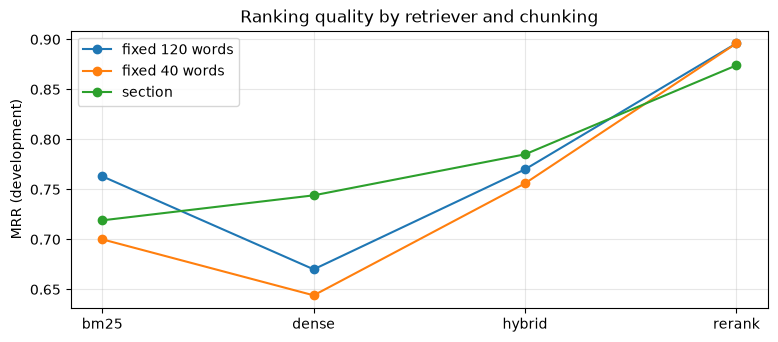

In [5]:
best = grid.iloc[0]
chosen_chunking, chosen_retriever = best["chunking"], best["retriever"]
print(f"chosen on development: {chosen_chunking} chunks, {chosen_retriever} retrieval")

fig, ax = plt.subplots(figsize=(9, 3.6))
for cname, part in grid.groupby("chunking"):
    part = part.set_index("retriever").loc[MODES]
    ax.plot(MODES, part["MRR"], marker="o", label=f"{cname}")
ax.set_ylabel("MRR (development)")
ax.set_title("Ranking quality by retriever and chunking")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3. When to say "not covered"

Seven questions ask for things the documents do not contain (prices, Wi-Fi passwords, the robot's
weight, shipping rates ...). A system that always answers would quote the closest passage as if it were the
answer. The assistant therefore answers only when the best passage scores above a **threshold**.

The development set holds just 2 unanswerable questions, too few to tune on. The threshold is set
from the **answerable** development questions instead: the 5th percentile of their best scores,
i.e. it is allowed to wrongly refuse about 1 answerable question in 20. Test shows what it catches.

threshold (score of the best passage) = -0.656


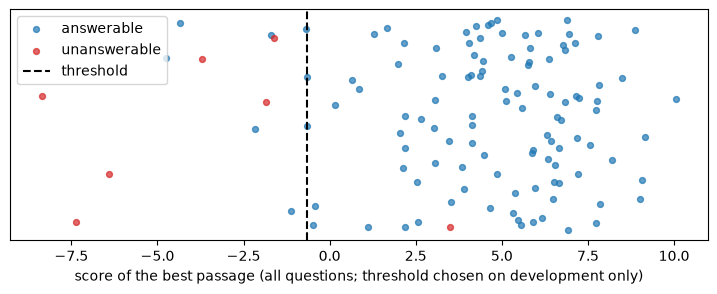

In [6]:
chosen = retrievers[(chosen_chunking, chosen_retriever)]
top_score = {q["id"]: chosen.search(q["question"], k=1)[0].score for q in questions}
dev_answerable = [top_score[q["id"]] for q in dev if q["sources"]]
threshold = float(np.percentile(dev_answerable, 5))
print(f"threshold (score of the best passage) = {threshold:.3f}")

fig, ax = plt.subplots(figsize=(9, 3))
for label, qs, color in [("answerable", [q for q in questions if q["sources"]], "tab:blue"),
                         ("unanswerable", [q for q in questions if not q["sources"]], "tab:red")]:
    ax.scatter([top_score[q["id"]] for q in qs], np.random.default_rng(0).uniform(0, 1, len(qs)),
               s=18, color=color, label=label, alpha=0.7)
ax.axvline(threshold, color="black", ls="--", label="threshold")
ax.set_yticks([])
ax.set_xlabel("score of the best passage (all questions; threshold chosen on development only)")
ax.legend(loc="upper left")
plt.show()

## 4. Test: retrieval, the not-covered decision and the answers

Scored once, with everything chosen above. For context the simplest setup (dense search over
section chunks, no reranker) is scored too.

**Answers** are scored against the reference answers with **token F1** (word overlap, as in the
SQuAD benchmark: a rough measure, since a correct answer in other words scores low) and by
whether they **cite a right section**. Two extractive styles are compared: the 3 best-matching
sentences of the retrieved sections, or the whole best section (up to 120 words). The style used
live is chosen on the development questions.

In [7]:
baseline = retrievers[("section", "dense")]
test_retrieval = pd.DataFrame(
    {
        f"chosen: {chosen_chunking} + {chosen_retriever}": retrieval_scores(lambda q: chosen.search(q, k=3), test, k=3),
        "simple: section + dense": retrieval_scores(lambda q: baseline.search(q, k=3), test, k=3),
    }
).T
test_retrieval

,hit@3,all@3,MRR,cite@1,words_read,hit@3 factual,hit@3 multi_hop,hit@3 procedural,ms_per_question,questions
chosen: section + rerank,0.970,0.910,0.908,0.851,173.0,0.979,0.833,1.000,853.1,67.0
simple: section + dense,0.896,0.836,0.761,0.642,179.0,0.894,0.833,0.929,33.5,67.0


In [8]:
settings = Settings(chunking=chosen_chunking, retriever=chosen_retriever, k=3,
                    candidates=defaults.candidates, threshold=round(threshold, 3))
answers, dev_answers, kbs = {}, {}, {}
for style in ["sentences", "section"]:
    settings.answer_style = style
    kb = KnowledgeBase(chunk_sets[chosen_chunking], chosen, Settings(**asdict(settings)))
    kbs[style] = kb
    dev_answers[style] = answer_scores(kb.ask, dev)  # the style is chosen here, on development
    answers[f"extractive: {style}"] = answer_scores(kb.ask, test)
best_style = max(dev_answers, key=lambda s: dev_answers[s]["answer_token_F1"] or 0)
print("answer style chosen on development (token F1):", best_style,
      {s: v["answer_token_F1"] for s, v in dev_answers.items()})
answer_table = pd.DataFrame(answers).T
answer_table

answer style chosen on development (token F1): section {'sentences': 0.328, 'section': 0.486}


,covered_decision_right,answer_token_F1,cites_a_right_section,cited_source_recall,ms_per_question,questions
extractive: sentences,0.944,0.347,0.873,0.815,935.4,71.0
extractive: section,0.944,0.495,0.841,0.775,698.2,71.0


In [9]:
unanswerable_test = [q for q in test if not q["sources"]]
refused = [q["question"] for q in unanswerable_test if top_score[q["id"]] < threshold]
wrongly_refused = [q["question"] for q in test if q["sources"] and top_score[q["id"]] < threshold]
print(f"unanswerable test questions refused: {len(refused)} of {len(unanswerable_test)}")
for text in refused:
    print("  refused  :", text)
for q in unanswerable_test:
    if q["question"] not in refused:
        print("  answered :", q["question"], f"(score {top_score[q['id']]:.2f})")
print(f"answerable test questions wrongly refused: {len(wrongly_refused)} of {sum(1 for q in test if q['sources'])}")
for text in wrongly_refused:
    print("  ", text)

unanswerable test questions refused: 4 of 4
  refused  : Who is the shift lead on Sunday?
  refused  : What is the maximum payload of a robot in kilograms?
  refused  : How much does it cost to ship a parcel with Swiftline Couriers?
  refused  : What is the phone number of RoadLink Parcel?
answerable test questions wrongly refused: 4 of 67
   Which cartons are used and how are they chosen?
   Which lot of a grocery item is picked first?
   How should we prepare for Black Friday?
   What causes repeated route deviations and how is it fixed?


## 5. Where retrieval still fails (test)

In [10]:
misses = []
for q in test:
    if not q["sources"]:
        continue
    hits = chosen.search(q["question"], k=3)
    wanted = {s.split("#")[1] for s in q["sources"]}
    got = [h.chunk.section_id for h in hits]
    if not wanted & {s for h in hits for s in h.chunk.sections}:
        misses.append({"type": q["type"], "question": q["question"], "needed": sorted(wanted), "retrieved": got})
print(f"{len(misses)} of {sum(1 for q in test if q['sources'])} answerable test questions without a right passage in the top 3")
pd.DataFrame(misses)

2 of 67 answerable test questions without a right passage in the top 3


,type,question,needed,retrieved
0,factual,How long does a robot spend picking and unloading?,[WM-5.5],"[SHP-3.2, SHP-6.1, RM-3]"
1,multi_hop,Why is a new order not given to a robot even though robots are free?,"[INV-5.3, SHP-3.2]","[SHP-6.1, SOP-07, SOP-08]"


## 6. Example answers (extractive, best style)

In [11]:
kb = kbs[best_style]
for text in [
    "What do we do when a robot overheats?",
    "How many charging bays are there?",
    "Can a person walk into a closed aisle?",
    "When is a product reordered?",
    "What is the Wi-Fi password for the robot network?",
]:
    out = kb.ask(text)
    print(f"Q: {text}\nA: {out['answer']}\n   sources: {[s['section_id'] for s in out['sources']]} · {out['ms']} ms\n")

Q: What do we do when a robot overheats?
A: Trigger: motor temperature above 60 C, or an overheating fault. Let the robot finish its current order: above 60 C it throttles to half speed automatically. If its temperature keeps rising above 70 C, pause it at the next safe stop (a parking bay or a wide highway lane, never a narrow aisle) and reassign its order. Do not assign new orders to the robot until its temperature is below 55 C. Resume it after cooling; if it overheats twice in one shift, send it for inspection (MG-6). [SOP-04]
   sources: ['SOP-04', 'MG-6.2', 'RM-5.3'] · 727 ms



Q: How many charging bays are there?
A: Each charger has three bays. If every bay is taken, a robot that only wants a top-up stays parked and tries again later; a low-battery robot keeps waiting for the nearest free bay. [RM-4.4]
   sources: ['RM-4.4', 'WM-2.6', 'SAF-3.4'] · 739 ms



Q: Can a person walk into a closed aisle?
A: An operator may close an aisle on request ("avoid Aisle 7"). Closing an aisle is only allowed when no robot or person is inside it and no robot is about to pick from it; otherwise pause the robots concerned first (SOP-05). [SAF-3.6]
   sources: ['SAF-3.6', 'SAF-3.2', 'WM-4.3'] · 738 ms



Q: When is a product reordered?
A: Reorder point: each SKU is reordered from its supplier when its inventory position (available to promise plus open purchase orders) falls to the reorder point = demand during the supplier lead time + safety stock. Safety stock = 1.65 x sqrt(hourly demand x lead time in hours), a 95 % cycle service level. [INV-6.3]
   sources: ['INV-6.3', 'SHP-6.5', 'INV-8.4'] · 458 ms



Q: What is the Wi-Fi password for the robot network?
A: The warehouse documents do not cover this. Ask the shift lead, or rephrase the question.
   sources: ['SAF-4.6', 'RM-7.3', 'RM-7.1'] · 563 ms



## 7. Optional: answers written by Claude

An LLM can combine several passages and phrase a procedure clearly; the extractive writer can only
quote. This cell runs only when an Anthropic API key is configured (`LLM_PROVIDER=anthropic`,
`LLM_API_KEY=...` in `.env`): it costs one API call per test question (56). The same retrieval,
threshold and scoring are used, so the difference is the writer alone.

In [12]:
llm_scores = None
if os.environ.get("LLM_PROVIDER", "").lower() == "anthropic":
    from ai.rag.generator import ClaudeGenerator

    kb_llm = KnowledgeBase(chunk_sets[chosen_chunking], chosen, Settings(**asdict(settings)),
                           generator=ClaudeGenerator(api_key=os.environ.get("LLM_API_KEY") or None))
    llm_scores = answer_scores(kb_llm.ask, test)
    display(pd.DataFrame({**answers, "Claude": llm_scores}).T)
else:
    print("Skipped: no LLM configured. Extractive answers are the default (free, offline, cannot invent facts).")

Skipped: no LLM configured. Extractive answers are the default (free, offline, cannot invent facts).


## 8. Save the settings and the report

The backend (`apps/backend/app/services/knowledge.py`) reads `models/rag_v1.json` for the chosen
chunking, retriever, k, threshold and answer style. The documents are re-read from the PDFs when
the backend starts (about 180 chunks take a few seconds to embed), or loaded into PostgreSQL with
pgvector by `scripts/ingest_documents.py --db`.

In [13]:
settings.answer_style = best_style
report = {
    "model": "rag_v1",
    "settings": asdict(settings),
    "documents": len({c.doc_id for c in chunk_sets["section"]}),
    "chunks": {name: len(ch) for name, ch in chunk_sets.items()},
    "split": {"dev": len(dev), "test": len(test)},
    "development_grid": grid.drop(columns=["hit + cite"]).to_dict("records"),
    "test_retrieval": test_retrieval.reset_index(names="setup").to_dict("records"),
    "test_answers": answers if llm_scores is None else {**answers, "Claude": llm_scores},
    "not_covered": {
        "threshold": round(threshold, 3),
        "unanswerable_refused": f"{len(refused)} of {len(unanswerable_test)}",
        "answerable_wrongly_refused": f"{len(wrongly_refused)} of {sum(1 for q in test if q['sources'])}",
    },
    "test_misses": misses,
}
(MODELS / "rag_v1.json").write_text(json.dumps(report, indent=2, default=float), encoding="utf-8")
print("Saved models/rag_v1.json:", report["settings"])

Saved models/rag_v1.json: {'chunking': 'section', 'retriever': 'rerank', 'k': 3, 'candidates': 10, 'threshold': -0.656, 'answer_style': 'section', 'embedder': 'sentence-transformers/all-MiniLM-L6-v2', 'reranker': 'cross-encoder/ms-marco-MiniLM-L6-v2'}


## 9. Conclusions

| Test (71 questions, never used for a choice) | Result |
|---|---|
| A right passage among the 3 retrieved (hit@3) | **0.970** (65 of 67 answerable) |
| Ranking (MRR) · first passage cites a right section (cite@1) | **0.908** · **0.851** (simple dense search: 0.761 · 0.642) |
| Unanswerable questions refused | 4 of 4 |
| Answerable questions wrongly refused | 4 of 67 (6 %) |
| Answer cites a right section · word overlap with the reference (token F1) | 0.841 · 0.495 |
| Time per question on a laptop CPU | ~0.6 s (the cross-encoder; dense search alone: 20 ms) |

* **Chunk by section, not by window.** Windows of 40 or 120 words find the right text about as
  often (hit@3 0.91-0.93 on development), but the first passage is a right citation only 27-47 %
  of the time, against 84 % for sections. For a system that must say *where* an answer comes from,
  the document's own structure is the better unit.
* **The reranker earns its cost.** It puts the right section **first** far more often than hybrid
  retrieval (cite@1 0.84 vs 0.73 on development), which is what the answer and its citation rely on.
* **"Not covered" is still the hardest part.** Retrieval scores of answerable and unanswerable
  questions overlap; the threshold (fixed on development data, not retuned on test) refused all 4
  unanswerable test questions but also 4 answerable ones. In the app the closest passages are
  shown even when the assistant refuses, so the operator can still read them.
* **A new document competes for words.** "How long does a robot spend picking and unloading?" now
  retrieves shipping sections (release, holds) before WM-5.5, because the shipping policies also
  talk about picking. More documents need more questions per topic to stay checked.
* **Codes inside tables are not sections.** The first run of v2 split the carrier table at the door
  codes SHIP-01 to SHIP-03 (they look like section ids); the chunker now only accepts ids with the
  document's own prefix (SHP-), which also brought back "When does the express truck leave?".
* **Extractive answers are faithful but rigid**: every word is from the documents and the citation
  is exact, but the writer cannot combine two sections or rephrase. Whole sections beat 3 loose
  sentences (token F1 0.495 vs 0.347) because procedures stay together. An LLM writer (section 7,
  optional) is the natural next step; it reads the same 3 passages under the same threshold.
* **Compared with v1** (6 documents, 94 questions): hit@3 0.962 → 0.970, cite@1 0.865 → 0.851 on a
  larger test set, with more refusals right (3 of 4 → 4 of 4) and fewer wrong (13 % → 6 %).
* **Limits:** 119 questions are few (one question = 1.4 points on test); the documents were written
  for this simulator; real manuals have scanned pages, figures and contradictions.